In [1]:
# 1. Importar librerías y comprobar el hardware
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import time

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponibles:", gpus if gpus else "Ninguna; se utilizará CPU")

# Evita que TensorFlow reserve toda la memoria de la GPU de una sola vez.
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass


TensorFlow: 2.21.0
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# 2. Cargar y preparar MNIST
(train_images, train_labels), (_, _) = tf.keras.datasets.mnist.load_data()

# Añadir canal de color y normalizar de [0, 255] a [-1, 1].
train_images = train_images.reshape(-1, 28, 28, 1).astype("float32")
train_images = (train_images - 127.5) / 127.5

BUFFER_SIZE = len(train_images)  # 60.000 imágenes
BATCH_SIZE = 256
EPOCHS = 10

train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_images)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Forma de las imágenes:", train_images.shape)
print("Lotes por época:", len(train_dataset))


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Forma de las imágenes: (60000, 28, 28, 1)
Lotes por época: 234


In [3]:
# 3. Construir el generador
def make_generator_model():
    model = tf.keras.Sequential(name="Generador")
    model.add(layers.Input(shape=(100,)))

    # Proyecta el vector de ruido a un mapa de características 7x7x256.
    model.add(layers.Dense(7 * 7 * 256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((7, 7, 256)))

    # Aumenta la resolución de 7x7 a 14x14.
    model.add(layers.Conv2DTranspose(
        128, kernel_size=5, strides=1, padding="same", use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Aumenta la resolución de 14x14 a 28x28.
    model.add(layers.Conv2DTranspose(
        64, kernel_size=5, strides=2, padding="same", use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Imagen final de 28x28 en el rango [-1, 1].
    model.add(layers.Conv2DTranspose(
        1, kernel_size=5, strides=2, padding="same",
        use_bias=False, activation="tanh"
    ))
    return model


# 4. Construir el discriminador
def make_discriminator_model():
    model = tf.keras.Sequential(name="Discriminador")
    model.add(layers.Input(shape=(28, 28, 1)))

    model.add(layers.Conv2D(64, kernel_size=5, strides=2, padding="same"))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, kernel_size=5, strides=2, padding="same"))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    # Sin sigmoid: la pérdida usa from_logits=True.
    model.add(layers.Dense(1))
    return model


generator = make_generator_model()
discriminator = make_discriminator_model()

generator.summary()
discriminator.summary()


Model: "Generador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

Model: "Discriminador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# 5. Definir las pérdidas y los optimizadores
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    # El generador intenta que el discriminador clasifique sus imágenes como reales.
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

noise_dim = 100
num_examples_to_generate = 16
seed = tf.random.normal([num_examples_to_generate, noise_dim])


In [5]:
# 6. Definir un paso de entrenamiento
@tf.function
def train_step(images):
    batch_size = tf.shape(images)[0]
    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


In [6]:
# 7. Función para visualizar imágenes generadas
def generate_and_show_images(model, epoch, test_input):
    predictions = model(test_input, training=False)

    fig = plt.figure(figsize=(5, 5))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        image = predictions[i, :, :, 0] * 127.5 + 127.5
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
        plt.axis("off")

    plt.suptitle(f"Imágenes generadas - Época {epoch}")
    plt.tight_layout()
    plt.show()


Iniciando entrenamiento...
Época 1/10 | Pérdida G: 0.7717 | Pérdida D: 1.0321 | Tiempo: 19.1 s
Época 2/10 | Pérdida G: 0.9490 | Pérdida D: 1.1725 | Tiempo: 11.9 s
Época 3/10 | Pérdida G: 1.1257 | Pérdida D: 0.9502 | Tiempo: 12.2 s
Época 4/10 | Pérdida G: 0.9197 | Pérdida D: 1.2378 | Tiempo: 12.7 s
Época 5/10 | Pérdida G: 0.9229 | Pérdida D: 1.2323 | Tiempo: 12.7 s


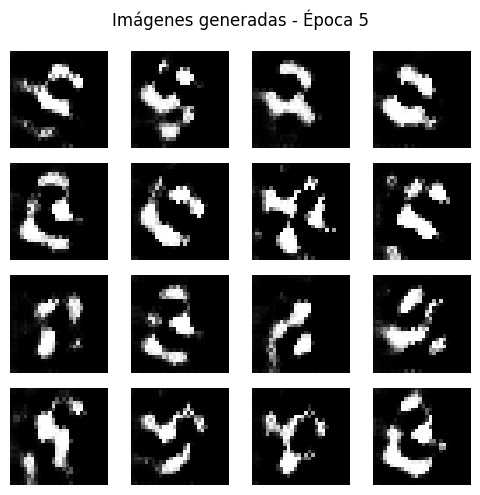

Época 6/10 | Pérdida G: 0.8949 | Pérdida D: 1.2575 | Tiempo: 13.0 s
Época 7/10 | Pérdida G: 0.9192 | Pérdida D: 1.2857 | Tiempo: 13.5 s
Época 8/10 | Pérdida G: 0.9339 | Pérdida D: 1.1861 | Tiempo: 14.1 s
Época 9/10 | Pérdida G: 0.9076 | Pérdida D: 1.2248 | Tiempo: 14.1 s
Época 10/10 | Pérdida G: 1.0373 | Pérdida D: 1.1502 | Tiempo: 13.6 s


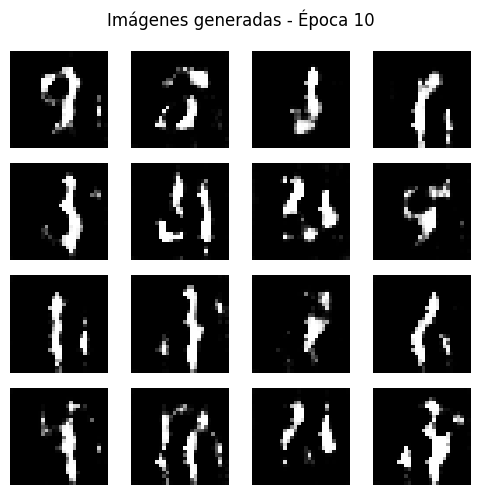

Entrenamiento finalizado.


In [7]:
# 8. Entrenar la GAN
def train(dataset, epochs):
    history = {"generator_loss": [], "discriminator_loss": []}

    for epoch in range(epochs):
        start_time = time.time()
        gen_metric = tf.keras.metrics.Mean()
        disc_metric = tf.keras.metrics.Mean()

        for step, image_batch in enumerate(dataset):
            gen_loss_value, disc_loss_value = train_step(image_batch)
            gen_metric.update_state(gen_loss_value)
            disc_metric.update_state(disc_loss_value)

        g_loss = float(gen_metric.result())
        d_loss = float(disc_metric.result())

        history["generator_loss"].append(g_loss)
        history["discriminator_loss"].append(d_loss)

        elapsed = time.time() - start_time
        print(
            f"Época {epoch + 1}/{epochs} | "
            f"Pérdida G: {g_loss:.4f} | "
            f"Pérdida D: {d_loss:.4f} | "
            f"Tiempo: {elapsed:.1f} s"
        )

        # Mostrar muestras cada 5 épocas y al finalizar.
        if (epoch + 1) % 5 == 0 or (epoch + 1) == epochs:
            generate_and_show_images(generator, epoch + 1, seed)

    return history


print("Iniciando entrenamiento...")
history = train(train_dataset, EPOCHS)
print("Entrenamiento finalizado.")


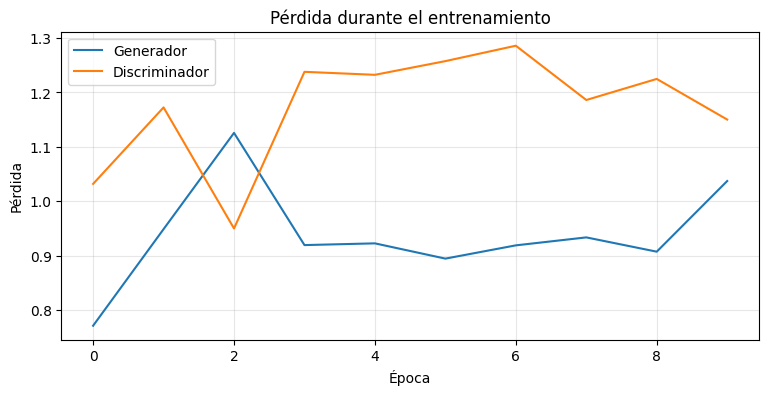

In [8]:
# 9. Graficar la evolución de las pérdidas
plt.figure(figsize=(9, 4))
plt.plot(history["generator_loss"], label="Generador")
plt.plot(history["discriminator_loss"], label="Discriminador")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


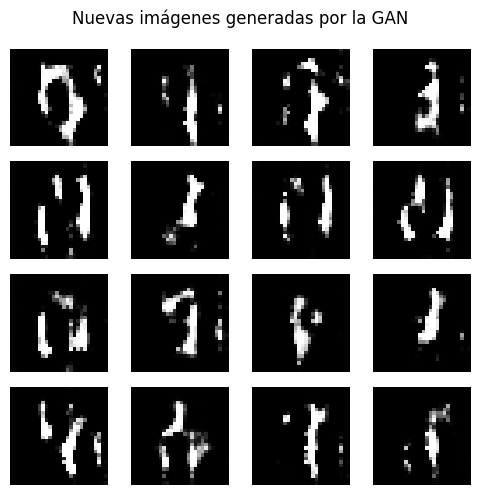

In [9]:
# 10. Generar un conjunto nuevo de 16 imágenes
new_noise = tf.random.normal([16, noise_dim])
generated_images = generator(new_noise, training=False)

fig = plt.figure(figsize=(5, 5))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    image = generated_images[i, :, :, 0] * 127.5 + 127.5
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.axis("off")

plt.suptitle("Nuevas imágenes generadas por la GAN")
plt.tight_layout()
plt.show()
